# Rainfall Prediction & Climate Modeling System
## RainVision — Metropolis Central Meteorological Station

This notebook implements an end-to-end meteorological machine learning pipeline for daily rainfall forecasting and storm severity classification based on 42 years (1985–Present, 15,279 records) of atmospheric observations.

### Objectives:
1. **Quantitative Depth Forecasting:** Predict continuous daily rainfall depth (mm) using baseline, linear, ensemble, and two-stage hurdle models.
2. **Storm Intensity Classification:** Classify weather into operational severity tiers: *Dry / Trace*, *Light*, *Moderate*, *Heavy*, and *Torrential*.
3. **Meteorological Explainability:** Interpret features via MDI importances and thermodynamic physics (Magnus-Tetens Dew Point calculation).
4. **Operational Deployment:** Provide leak-free time-series validation, model serialization, and automated civic safety advisories.

In [22]:
# =====================================================================
# 1. Environment Setup & Core Libraries
# =====================================================================
import os
import sys
import json
import time
import datetime
from pathlib import Path

# Project paths
PROJECT_ROOT = Path("..").resolve() if Path("../data").exists() else Path(".").resolve()
for folder in ["data", "models", "outputs/figures", "outputs/reports", "outputs/predictions"]:
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)

# Data manipulation & numerical computing
import numpy as np
import pandas as pd
import joblib

# Visualization
import matplotlib
if not ("google.colab" in sys.modules or "ipykernel" in sys.modules):
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10
plt.rcParams["figure.dpi"] = 150

# Machine learning modeling suite
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestRegressor, RandomForestClassifier,
    GradientBoostingRegressor, GradientBoostingClassifier
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Dataset Ingestion

We load the long-term historical meteorological dataset from `data/RainVision_Historical_1985_to_Today.xlsx`.
The dataset covers 42 years of daily weather recordings for Metropolis Central Station ($23.0225^\circ\text{ N}, 72.5714^\circ\text{ E}$).

In [23]:
# =====================================================================
# 2. Data Loading
# =====================================================================
candidate_paths = [
    PROJECT_ROOT / "data" / "RainVision_Historical_1985_to_Today.xlsx",
    PROJECT_ROOT / "RainVision_Historical_1985_to_Today.xlsx",
    Path("data/RainVision_Historical_1985_to_Today.xlsx"),
    Path("../data/RainVision_Historical_1985_to_Today.xlsx")
]

data_path = None
for p in candidate_paths:
    if p.exists():
        data_path = p
        break

if data_path is None:
    raise FileNotFoundError("Master Excel dataset not found. Please place RainVision_Historical_1985_to_Today.xlsx in data/.")

df_raw = pd.read_excel(data_path, sheet_name="Rainfall_Data_1985_to_Today")
print(f"Dataset successfully loaded: {df_raw.shape[0]:,} records × {df_raw.shape[1]} columns")
print(f"Date range: {df_raw['date'].min()} to {df_raw['date'].max()} ({df_raw['date'].nunique():,} days)")
display(df_raw.head(5))

Dataset successfully loaded: 15,279 records × 13 columns
Date range: 1985-01-01 to 2026-10-31 (15,279 days)


,date,year,month,day,location,temperature,humidity,pressure,wind_speed,previous_rainfall,rainfall,rainfall_category,is_monsoon
0,1985-01-01,1985,1,1,Metropolis Central Station,17.4,42,1008.6,11.1,0.0,0.0,Dry / Trace,0
1,1985-01-02,1985,1,2,Metropolis Central Station,17.0,42,1010.4,14.8,0.0,0.0,Dry / Trace,0
2,1985-01-03,1985,1,3,Metropolis Central Station,18.3,51,1010.4,17.8,0.0,0.0,Dry / Trace,0
3,1985-01-04,1985,1,4,Metropolis Central Station,19.4,53,1008.6,10.2,0.0,0.0,Dry / Trace,0
4,1985-01-05,1985,1,5,Metropolis Central Station,19.5,41,1008.1,10.3,0.0,0.0,Dry / Trace,0


## 3. Data Overview & Zero-Inflation Audit

We inspect variable types, summary statistics, and quantify the zero-inflation characteristic of semi-arid and monsoonal regimes.

In [24]:
# =====================================================================
# 3. Data Inspection & Zero-Inflation Breakdown
# =====================================================================
print("--- DATASET SUMMARY ---")
df_raw.info()

print("\n--- DESCRIPTIVE STATISTICS ---")
display(df_raw[["temperature", "humidity", "pressure", "wind_speed", "previous_rainfall", "rainfall"]].describe().round(2))

total_obs = len(df_raw)
dry_obs = (df_raw["rainfall"] <= 0.05).sum()
wet_obs = (df_raw["rainfall"] > 0.05).sum()
heavy_obs = (df_raw["rainfall"] >= 50.0).sum()

print("\n--- ZERO-INFLATION BREAKDOWN ---")
print(f"Total Observation Days         : {total_obs:,}")
print(f"Dry / Trace Days (<= 0.05 mm)  : {dry_obs:,} ({dry_obs / total_obs * 100:.2f}%)")
print(f"Active Rain Days (> 0.05 mm)   : {wet_obs:,} ({wet_obs / total_obs * 100:.2f}%)")
print(f"Severe Storm Days (>= 50.0 mm) : {heavy_obs:,} ({heavy_obs / total_obs * 100:.2f}%)")

--- DATASET SUMMARY ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15279 entries, 0 to 15278
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               15279 non-null  object 
 1   year               15279 non-null  int64  
 2   month              15279 non-null  int64  
 3   day                15279 non-null  int64  
 4   location           15279 non-null  object 
 5   temperature        15279 non-null  float64
 6   humidity           15279 non-null  int64  
 7   pressure           15279 non-null  float64
 8   wind_speed         15279 non-null  float64
 9   previous_rainfall  15279 non-null  float64
 10  rainfall           15279 non-null  float64
 11  rainfall_category  15279 non-null  object 
 12  is_monsoon         15279 non-null  int64  
dtypes: float64(5), int64(5), object(3)
memory usage: 1.5+ MB

--- DESCRIPTIVE STATISTICS ---


,temperature,humidity,pressure,wind_speed,previous_rainfall,rainfall
count,15279.00,15279.00,15279.00,15279.00,15279.00,15279.00
mean,27.20,53.79,1002.18,14.07,2.09,2.09
std,4.35,18.77,5.40,4.20,10.33,10.33
min,13.60,8.00,980.70,5.40,0.00,0.00
25%,24.10,40.00,997.80,10.80,0.00,0.00
50%,27.50,51.00,1002.40,13.40,0.00,0.00
75%,30.40,69.00,1006.80,16.60,0.10,0.10
max,38.60,98.00,1015.40,57.50,339.90,339.90



--- ZERO-INFLATION BREAKDOWN ---
Total Observation Days         : 15,279
Dry / Trace Days (<= 0.05 mm)  : 11,214 (73.39%)
Active Rain Days (> 0.05 mm)   : 4,065 (26.61%)
Severe Storm Days (>= 50.0 mm) : 120 (0.79%)


## 4. Data Cleaning & Domain Boundary Validation

We apply the quality assurance pipeline:
1. **Deduplication:** Remove any duplicate dates.
2. **Chronological Sorting:** Order strictly by timestamp.
3. **Physical Domain Bounds:** Enforce physical boundaries ($0 \le T \le 55^\circ\text{C}$, $0\% \le RH \le 100\%$, $850 \le P \le 1100\text{ hPa}$, $W \ge 0$, $\text{Rain} \ge 0$).
4. **Zero-Leakage Imputation:** Forward-fill telemetry gaps to prevent lookahead bias.
5. **Tukey Outlier Analysis:** Identify and preserve genuine cyclonic depressions.

In [25]:
# =====================================================================
# 4. Cleaning & Domain Boundary Enforcement
# =====================================================================
df_clean = df_raw.copy()
df_clean["date"] = pd.to_datetime(df_clean["date"])
df_clean = df_clean.drop_duplicates(subset=["date"]).sort_values("date").reset_index(drop=True)

# Enforce physical atmospheric boundaries
df_clean["temperature"] = df_clean["temperature"].clip(0.0, 55.0)
df_clean["humidity"] = df_clean["humidity"].clip(0.0, 100.0)
df_clean["pressure"] = df_clean["pressure"].clip(850.0, 1100.0)
df_clean["wind_speed"] = df_clean["wind_speed"].clip(0.0, 180.0)
df_clean["rainfall"] = df_clean["rainfall"].clip(lower=0.0)
df_clean["previous_rainfall"] = df_clean["previous_rainfall"].clip(lower=0.0)

# Forward-fill gaps
df_clean = df_clean.ffill().bfill()

# Tukey IQR Analysis
q25 = df_clean["rainfall"].quantile(0.25)
q75 = df_clean["rainfall"].quantile(0.75)
iqr = q75 - q25
upper_bound = q75 + 1.5 * iqr
storm_days = df_clean[df_clean["rainfall"] > upper_bound]

print(f"Cleaning complete: {len(df_clean):,} validated observations.")
print(f"Tukey Upper Bound: {upper_bound:.2f} mm | Storm days preserved: {len(storm_days):,}")
display(storm_days.sort_values("rainfall", ascending=False)[["date", "temperature", "humidity", "pressure", "wind_speed", "rainfall"]].head(5))

Cleaning complete: 15,279 validated observations.
Tukey Upper Bound: 0.25 mm | Storm days preserved: 3,408


,date,temperature,humidity,pressure,wind_speed,rainfall
11890,2017-07-22,25.5,91,992.1,25.3,339.9
2061,1990-08-24,25.3,96,992.2,31.0,274.9
7880,2006-07-30,24.9,95,991.0,23.1,249.7
4557,1997-06-24,26.6,92,989.1,38.2,247.6
7897,2006-08-16,25.2,96,991.2,21.7,190.6


## 5. Exploratory Data Analysis (EDA)

Visualizing the key characteristics of precipitation in Western India:
- Zero-inflation & heavy-tail distribution
- Bivariate scatter relationships with humidity, pressure, temperature, and wind speed
- 42-year annual rainfall anomaly timeline
- Monthly monsoon seasonality & correlation heatmap

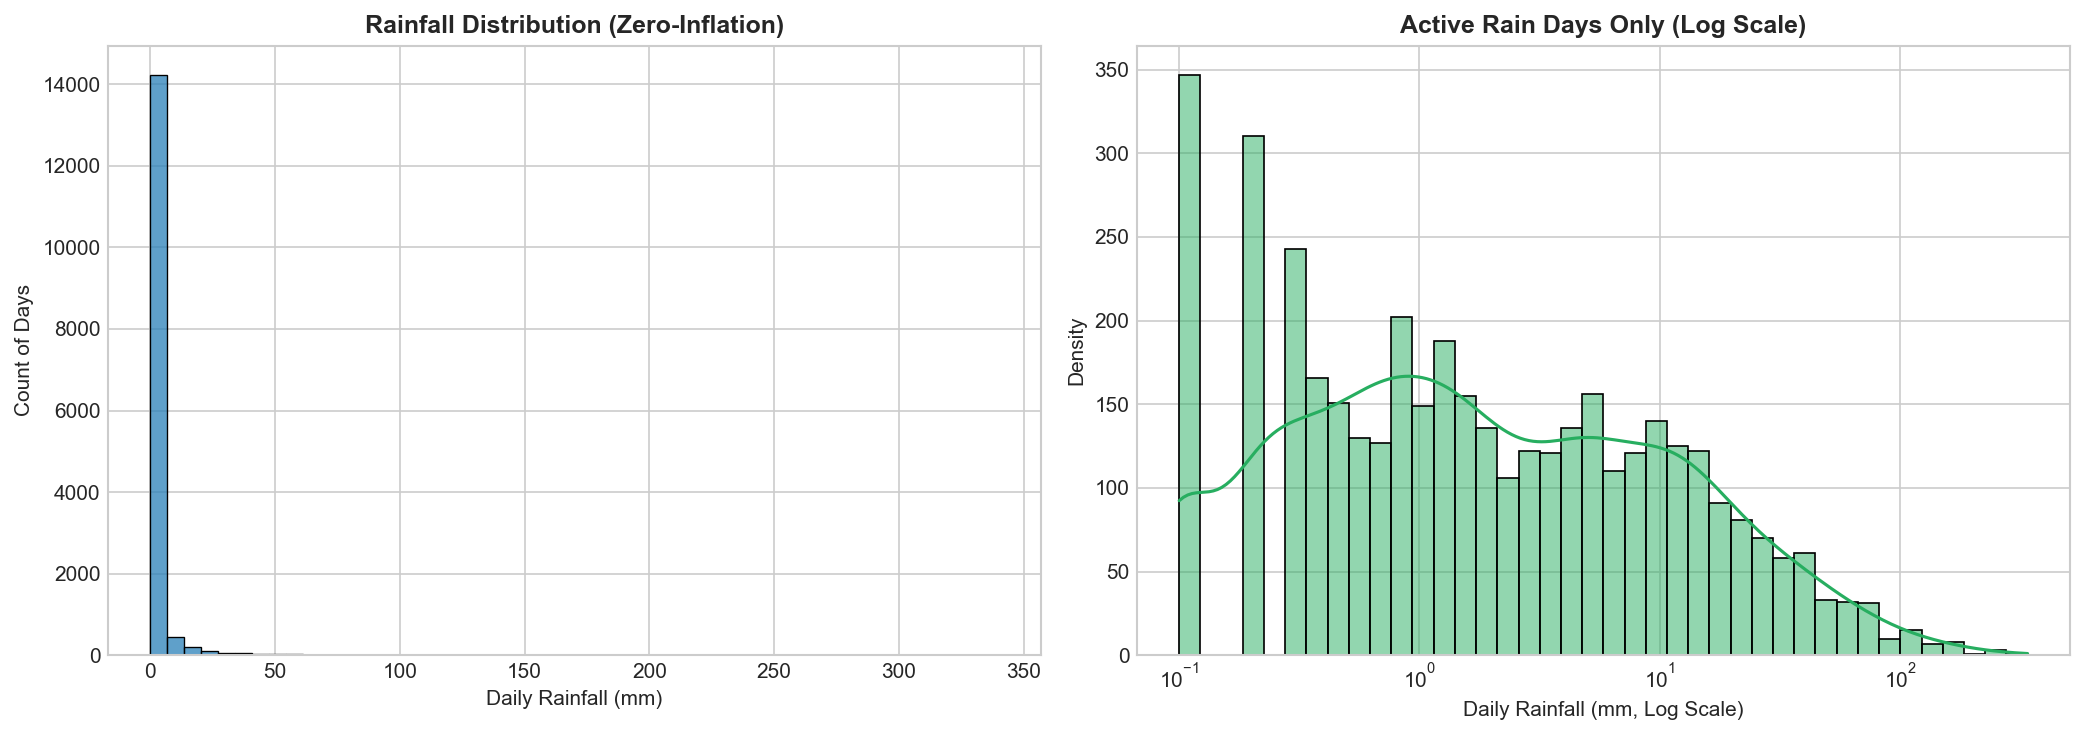

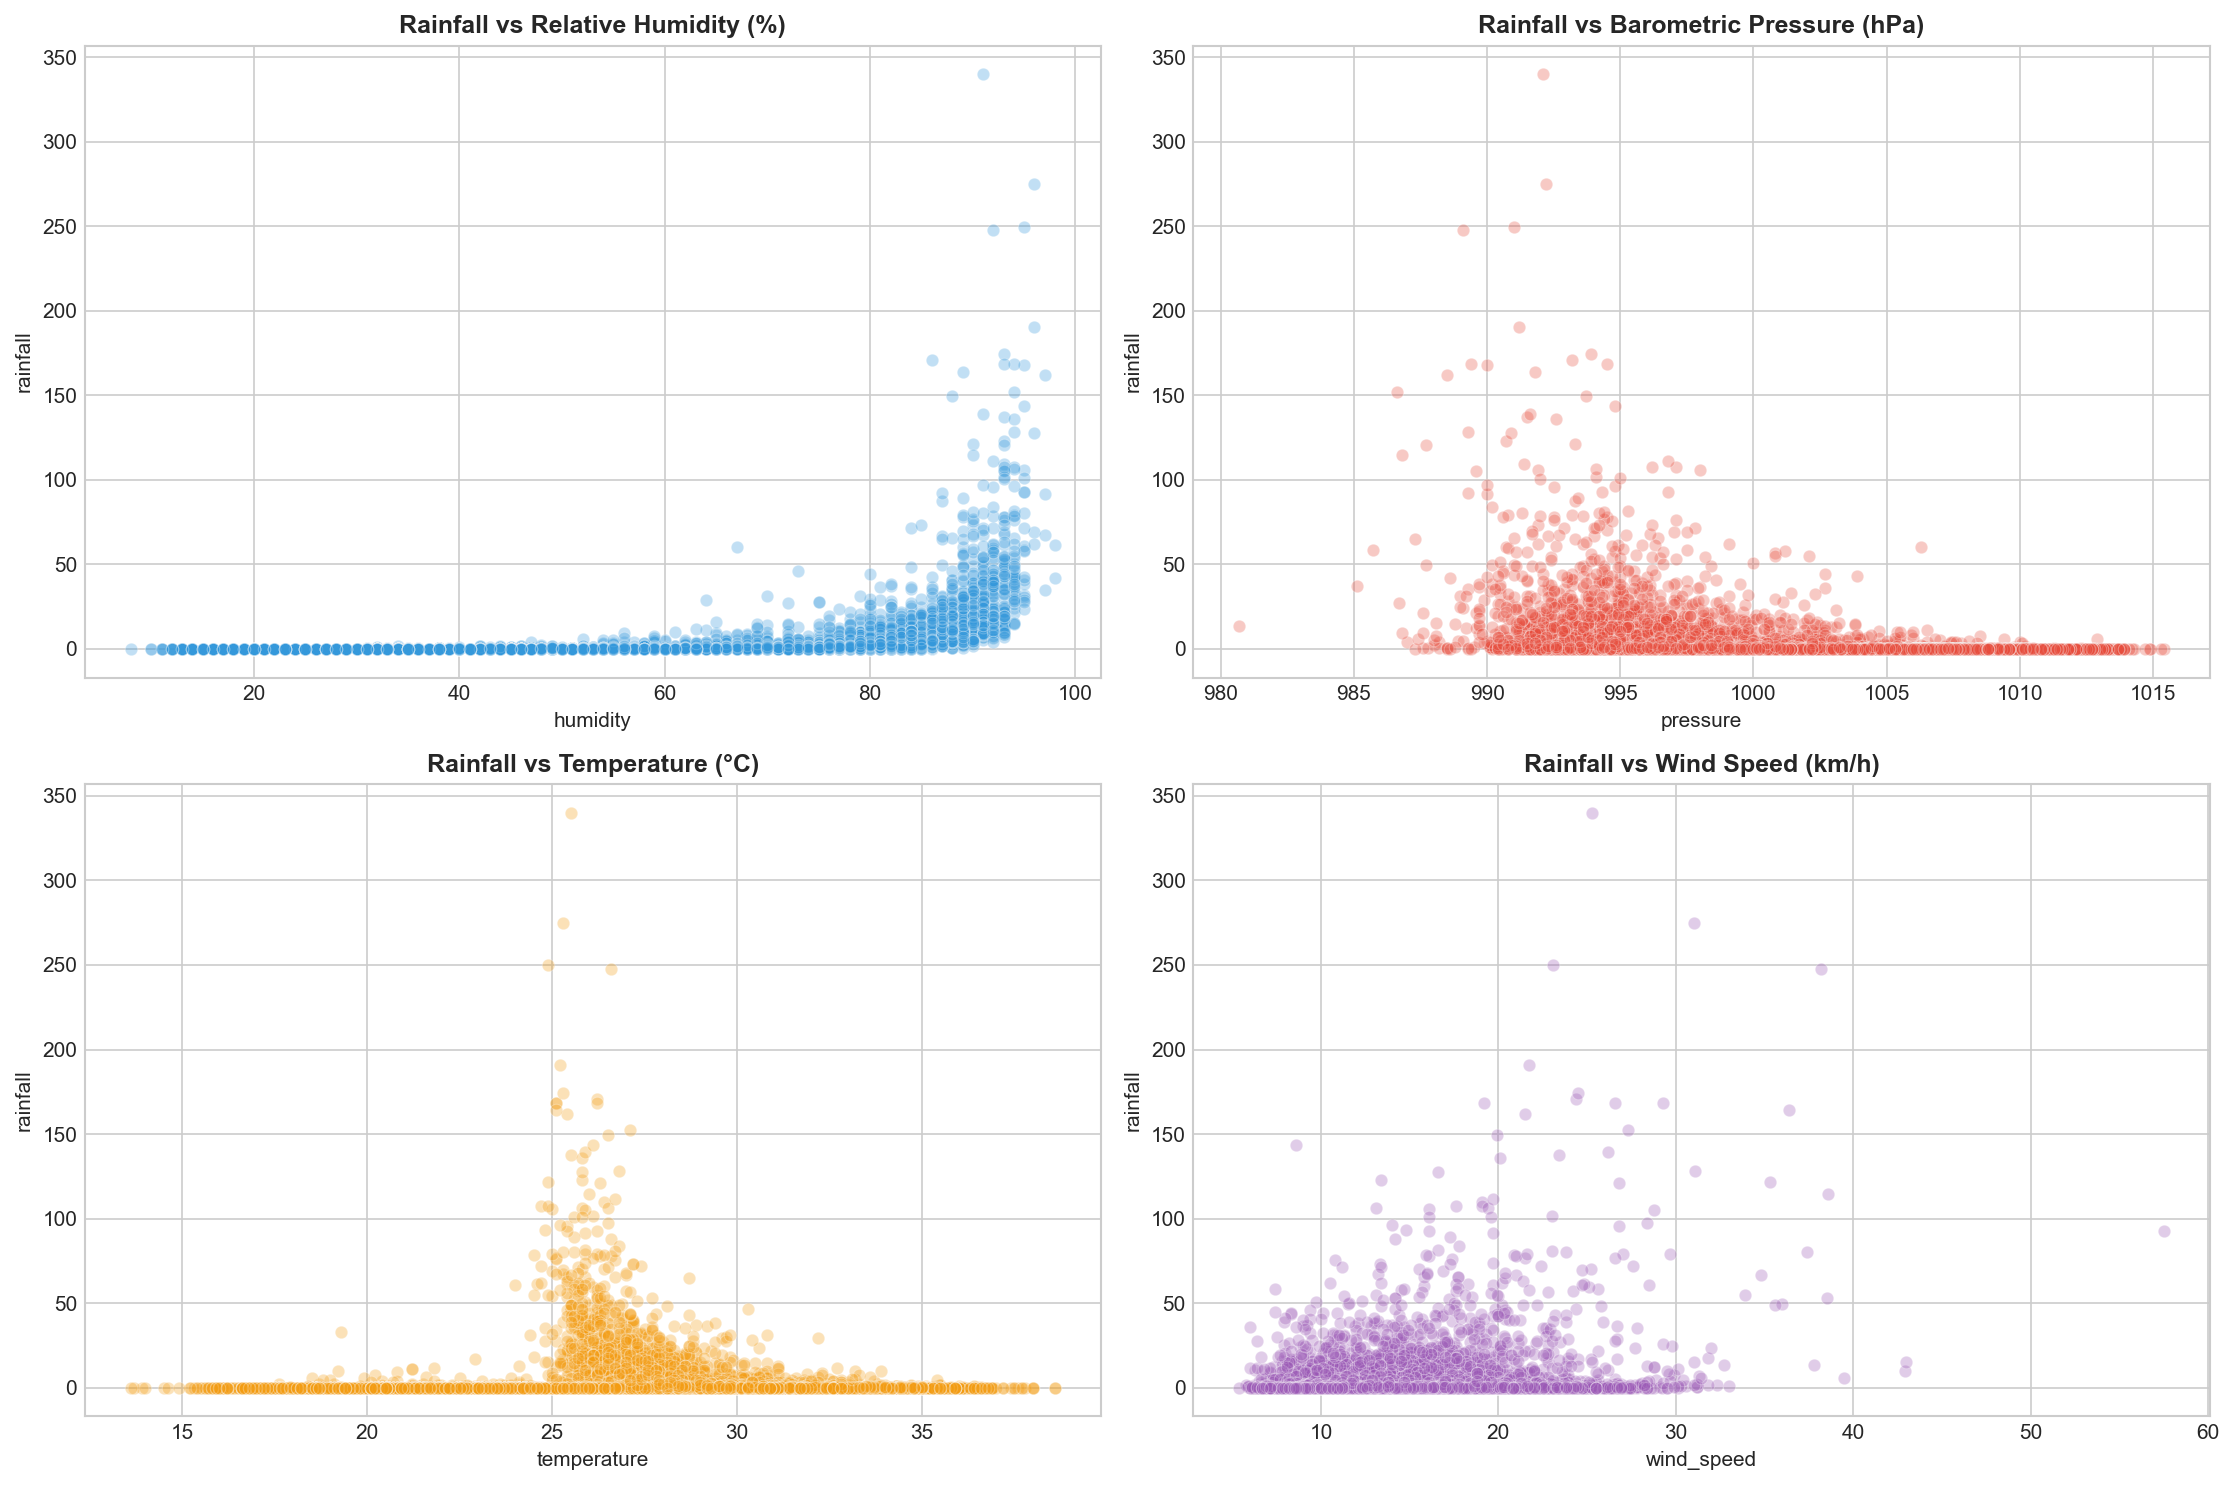

C:\Users\makmu\AppData\Local\Temp\ipykernel_16612\3867790451.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=annual_tot, x="year", y="rainfall", palette=bar_colors, ax=ax)


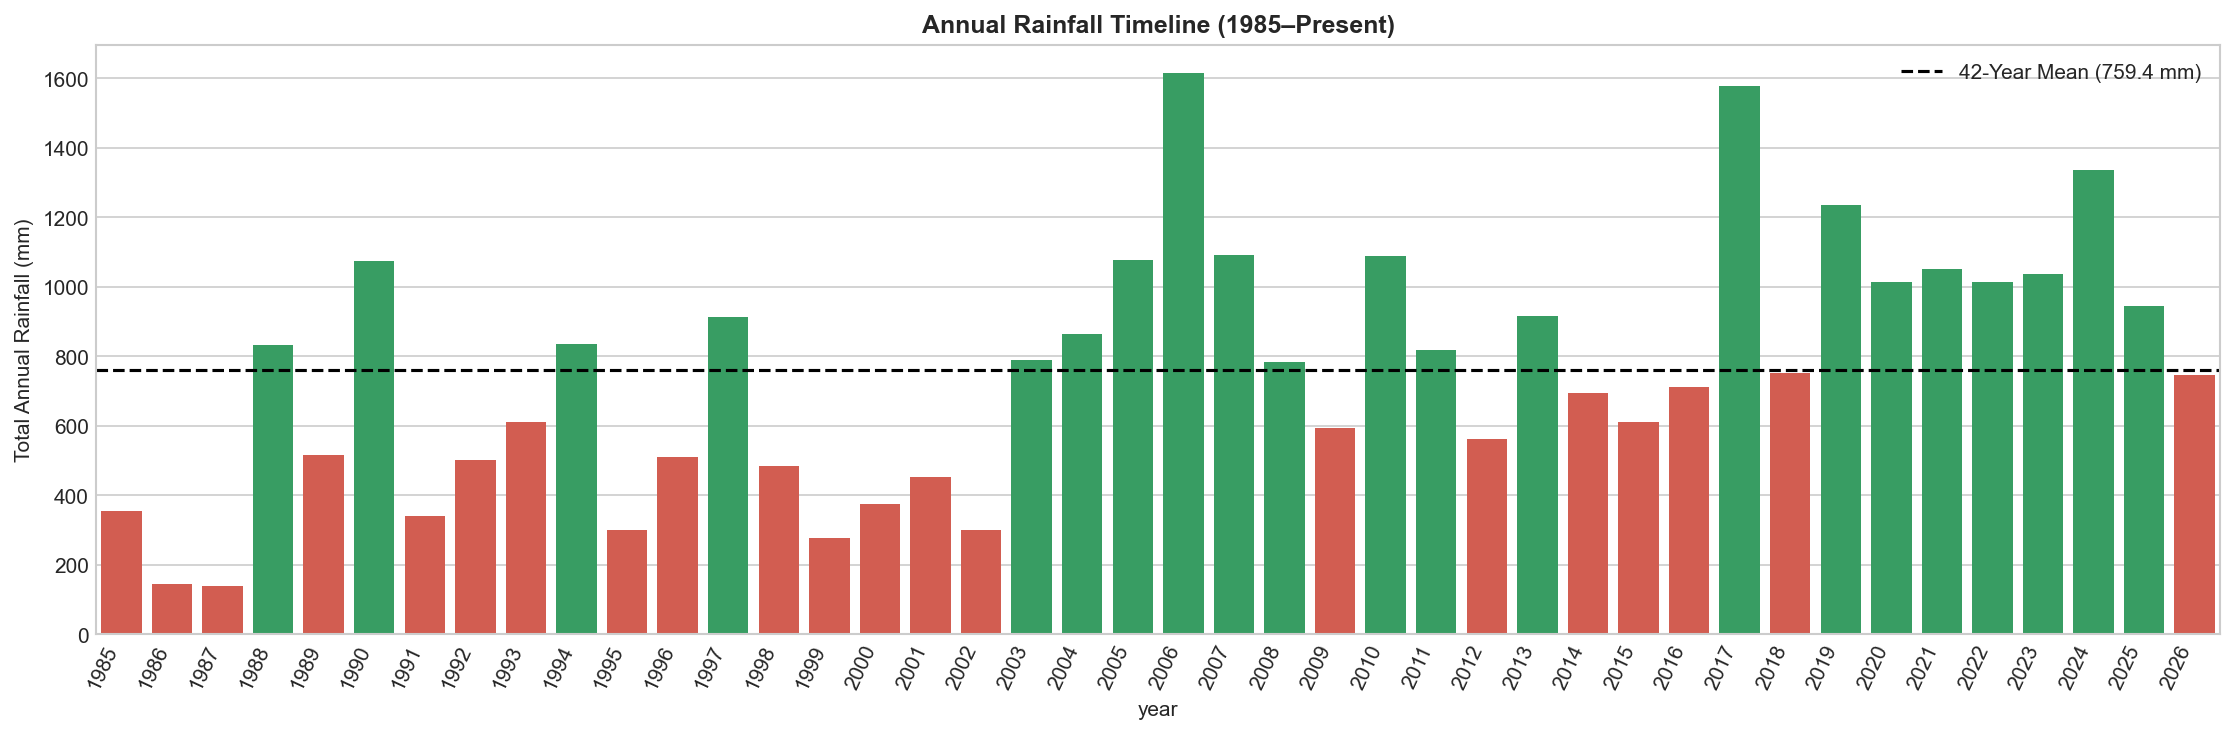

C:\Users\makmu\AppData\Local\Temp\ipykernel_16612\3867790451.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="month", y="rainfall", showfliers=False, palette="YlGnBu", ax=axes[0])
C:\Users\makmu\AppData\Local\Temp\ipykernel_16612\3867790451.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(months)


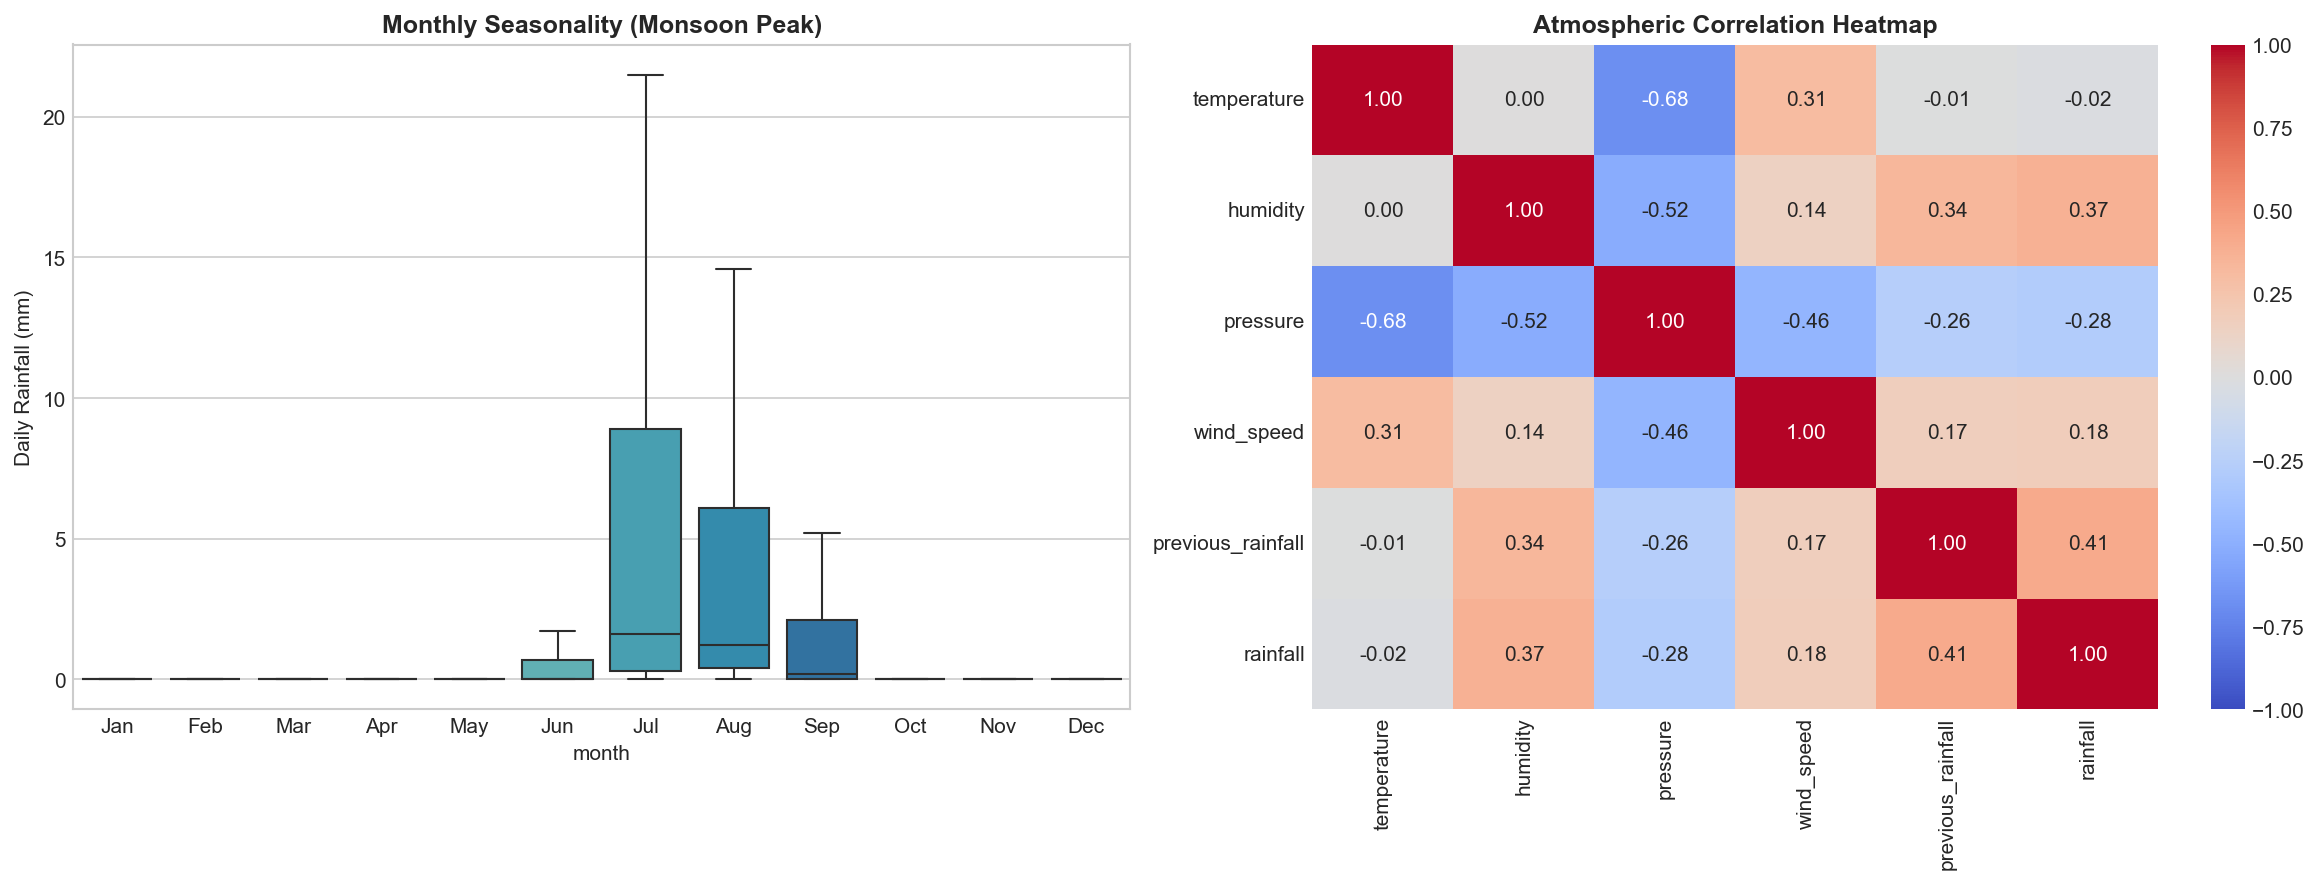

In [26]:
# =====================================================================
# 5. Exploratory Data Visualizations
# =====================================================================
# Distribution Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_clean["rainfall"], bins=50, color="#2980b9", ax=axes[0])
axes[0].set_title("Rainfall Distribution (Zero-Inflation)", fontweight="bold")
axes[0].set_xlabel("Daily Rainfall (mm)")
axes[0].set_ylabel("Count of Days")

wet_rain = df_clean[df_clean["rainfall"] > 0.05]["rainfall"]
sns.histplot(wet_rain, bins=40, kde=True, color="#27ae60", log_scale=True, ax=axes[1])
axes[1].set_title("Active Rain Days Only (Log Scale)", fontweight="bold")
axes[1].set_xlabel("Daily Rainfall (mm, Log Scale)")
axes[1].set_ylabel("Density")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs" / "figures" / "eda_distribution.png", dpi=150)
plt.show()

# Bivariate Atmospheric Relationships
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.scatterplot(data=df_clean, x="humidity", y="rainfall", alpha=0.3, color="#3498db", ax=axes[0, 0])
axes[0, 0].set_title("Rainfall vs Relative Humidity (%)", fontweight="bold")

sns.scatterplot(data=df_clean, x="pressure", y="rainfall", alpha=0.3, color="#e74c3c", ax=axes[0, 1])
axes[0, 1].set_title("Rainfall vs Barometric Pressure (hPa)", fontweight="bold")

sns.scatterplot(data=df_clean, x="temperature", y="rainfall", alpha=0.3, color="#f39c12", ax=axes[1, 0])
axes[1, 0].set_title("Rainfall vs Temperature (°C)", fontweight="bold")

sns.scatterplot(data=df_clean, x="wind_speed", y="rainfall", alpha=0.3, color="#9b59b6", ax=axes[1, 1])
axes[1, 1].set_title("Rainfall vs Wind Speed (km/h)", fontweight="bold")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs" / "figures" / "eda_bivariate.png", dpi=150)
plt.show()

# 42-Year Annual Climatology & Seasonality
df_clean["year"] = df_clean["date"].dt.year
df_clean["month"] = df_clean["date"].dt.month
annual_tot = df_clean.groupby("year")["rainfall"].sum().reset_index()
mean_ann = annual_tot["rainfall"].mean()

fig, ax = plt.subplots(figsize=(15, 5))
bar_colors = ["#27ae60" if r >= mean_ann else "#e74c3c" for r in annual_tot["rainfall"]]
sns.barplot(data=annual_tot, x="year", y="rainfall", palette=bar_colors, ax=ax)
ax.axhline(mean_ann, color="black", linestyle="--", label=f"42-Year Mean ({mean_ann:.1f} mm)")
ax.set_title("Annual Rainfall Timeline (1985–Present)", fontweight="bold")
ax.set_ylabel("Total Annual Rainfall (mm)")
plt.xticks(rotation=65, ha="right")
ax.legend()
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs" / "figures" / "eda_annual_totals.png", dpi=150)
plt.show()

# Monthly Boxplot & Heatmap
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
sns.boxplot(data=df_clean, x="month", y="rainfall", showfliers=False, palette="YlGnBu", ax=axes[0])
axes[0].set_xticklabels(months)
axes[0].set_title("Monthly Seasonality (Monsoon Peak)", fontweight="bold")
axes[0].set_ylabel("Daily Rainfall (mm)")

corr = df_clean[["temperature", "humidity", "pressure", "wind_speed", "previous_rainfall", "rainfall"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Atmospheric Correlation Heatmap", fontweight="bold")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs" / "figures" / "eda_seasonality_corr.png", dpi=150)
plt.show()

## 6. Feature Engineering

We construct **17 domain-specific features**:
1. Solar cycle angles: $\sin(\text{DOY})$ and $\cos(\text{DOY})$
2. Antecedent rainfall lags: `rain_lag_1`, `rain_lag_2`, `rain_lag_3`
3. Rolling moisture: 7-day mean/sum/max and 14-day mean
4. Barometric pressure trend: `pressure_diff_1`
5. Antecedent conditions: `temp_lag_1`, `humidity_lag_1`
6. Monsoon flag: `is_monsoon` (June–September)
7. Operational intensity categories: *Dry / Trace*, *Light*, *Moderate*, *Heavy*, *Torrential*

In [27]:
# =====================================================================
# 6. Feature Construction Pipeline
# =====================================================================
def categorize_rainfall(y: float) -> str:
    if y <= 0.05:
        return "Dry / Trace"
    elif y <= 2.5:
        return "Light"
    elif y <= 15.0:
        return "Moderate"
    elif y <= 50.0:
        return "Heavy"
    else:
        return "Torrential"

def extract_features(df_in: pd.DataFrame) -> pd.DataFrame:
    df = df_in.copy().sort_values("date").reset_index(drop=True)
    doy = df["date"].dt.dayofyear
    
    # Solar cyclical coordinates
    df["sin_day_of_year"] = np.sin(2 * np.pi * doy / 365.25)
    df["cos_day_of_year"] = np.cos(2 * np.pi * doy / 365.25)
    
    # Antecedent lags
    df["rain_lag_1"] = df["rainfall"].shift(1).fillna(0.0)
    df["rain_lag_2"] = df["rainfall"].shift(2).fillna(0.0)
    df["rain_lag_3"] = df["rainfall"].shift(3).fillna(0.0)
    
    # Multi-day rolling moisture
    df["rain_roll_mean_7"] = df["rainfall"].shift(1).rolling(7, min_periods=1).mean().fillna(0.0)
    df["rain_roll_sum_7"] = df["rainfall"].shift(1).rolling(7, min_periods=1).sum().fillna(0.0)
    df["rain_roll_max_7"] = df["rainfall"].shift(1).rolling(7, min_periods=1).max().fillna(0.0)
    df["rain_roll_mean_14"] = df["rainfall"].shift(1).rolling(14, min_periods=1).mean().fillna(0.0)
    
    # Atmospheric trends
    df["temp_lag_1"] = df["temperature"].shift(1).bfill()
    df["humidity_lag_1"] = df["humidity"].shift(1).bfill()
    df["pressure_diff_1"] = (df["pressure"] - df["pressure"].shift(1)).fillna(0.0)
    
    # Monsoon season indicator
    df["is_monsoon"] = df["date"].dt.month.isin([6, 7, 8, 9]).astype(int)
    
    # Classification category
    df["rainfall_category"] = df["rainfall"].apply(categorize_rainfall)
    return df

df_features = extract_features(df_clean)

FEATURE_COLUMNS = [
    "temperature", "humidity", "pressure", "wind_speed",
    "rain_lag_1", "rain_lag_2", "rain_lag_3",
    "rain_roll_mean_7", "rain_roll_sum_7", "rain_roll_max_7", "rain_roll_mean_14",
    "temp_lag_1", "humidity_lag_1", "pressure_diff_1",
    "sin_day_of_year", "cos_day_of_year", "is_monsoon"
]

print(f"Features created: {len(FEATURE_COLUMNS)} predictors.")
display(df_features[FEATURE_COLUMNS + ["rainfall", "rainfall_category"]].head(5))

Features created: 17 predictors.


,temperature,humidity,pressure,wind_speed,rain_lag_1,rain_lag_2,rain_lag_3,rain_roll_mean_7,rain_roll_sum_7,rain_roll_max_7,rain_roll_mean_14,temp_lag_1,humidity_lag_1,pressure_diff_1,sin_day_of_year,cos_day_of_year,is_monsoon,rainfall,rainfall_category
0,17.4,42,1008.6,11.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.4,42.0,0.0,0.017202,0.999852,0,0.0,Dry / Trace
1,17.0,42,1010.4,14.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.4,42.0,1.8,0.034398,0.999408,0,0.0,Dry / Trace
2,18.3,51,1010.4,17.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.0,42.0,0.0,0.051584,0.998669,0,0.0,Dry / Trace
3,19.4,53,1008.6,10.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.3,51.0,-1.8,0.068755,0.997634,0,0.0,Dry / Trace
4,19.5,41,1008.1,10.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19.4,53.0,-0.5,0.085906,0.996303,0,0.0,Dry / Trace


## 7. Chronological Partitioning

To avoid temporal lookahead data leakage, we partition the dataset strictly by date:
- **Train (70%):** 1985–2014
- **Validation (15%):** 2014–2020
- **Held-out Test (15%):** 2020–Present

Train Partition : 10,695 days (1985-01-01 to 2014-04-13)
Val Partition   : 2,291 days (2014-04-14 to 2020-07-21)
Test Partition  : 2,293 days (2020-07-22 to 2026-10-31)


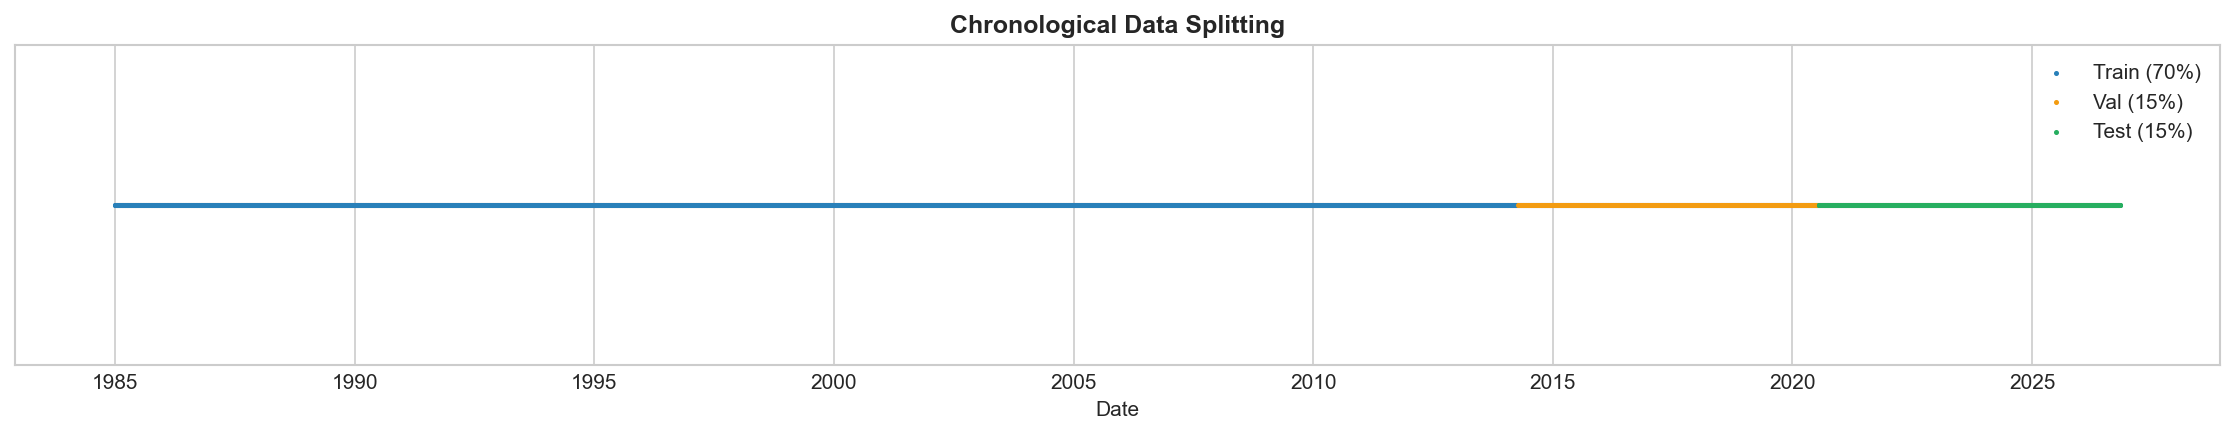

In [28]:
# =====================================================================
# 7. Train / Validation / Test Splitting
# =====================================================================
n_total = len(df_features)
n_train = int(n_total * 0.70)
n_val = int(n_total * 0.15)

train_df = df_features.iloc[:n_train].copy().reset_index(drop=True)
val_df = df_features.iloc[n_train:n_train + n_val].copy().reset_index(drop=True)
test_df = df_features.iloc[n_train + n_val:].copy().reset_index(drop=True)

X_train, y_train_reg, y_train_clf = train_df[FEATURE_COLUMNS], train_df["rainfall"], train_df["rainfall_category"]
X_val, y_val_reg, y_val_clf = val_df[FEATURE_COLUMNS], val_df["rainfall"], val_df["rainfall_category"]
X_test, y_test_reg, y_test_clf = test_df[FEATURE_COLUMNS], test_df["rainfall"], test_df["rainfall_category"]

print(f"Train Partition : {len(train_df):,} days ({train_df['date'].min().date()} to {train_df['date'].max().date()})")
print(f"Val Partition   : {len(val_df):,} days ({val_df['date'].min().date()} to {val_df['date'].max().date()})")
print(f"Test Partition  : {len(test_df):,} days ({test_df['date'].min().date()} to {test_df['date'].max().date()})")

# Split Timeline Visualization
fig, ax = plt.subplots(figsize=(15, 3))
ax.scatter(train_df["date"], [1]*len(train_df), color="#2980b9", s=2, label="Train (70%)")
ax.scatter(val_df["date"], [1]*len(val_df), color="#f39c12", s=2, label="Val (15%)")
ax.scatter(test_df["date"], [1]*len(test_df), color="#27ae60", s=2, label="Test (15%)")
ax.set_yticks([])
ax.set_title("Chronological Data Splitting", fontweight="bold")
ax.set_xlabel("Date")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 8. Rainfall Depth Regression Models

We train and benchmark quantitative models:
1. **Baseline Mean Regressor**
2. **Baseline Persistence (Lag-1)**
3. **Linear Regression (OLS)**
4. **Ridge Regression** (with `StandardScaler`)
5. **Decision Tree Regressor**
6. **Random Forest Regressor**
7. **Gradient Boosting Regressor**
8. **Two-Stage Hurdle Model** (Stage 1 Rain Gating + Stage 2 Positive Depth Estimation)

--- REGRESSION BENCHMARK RESULTS (TEST SET) ---


,Model,MAE (mm),RMSE (mm),R² Score,Wet-Day MAE (mm)
7,Two-Stage Hurdle Model,1.757,6.407,0.6406,4.862
5,Random Forest,1.797,6.727,0.6038,4.929
6,Gradient Boosting,1.873,7.368,0.5247,5.070
2,Linear Regression (OLS),2.833,8.381,0.3849,6.563
3,Ridge Regression,2.828,8.393,0.3831,6.572
4,Decision Tree,2.050,9.685,0.1787,5.637
0,Baseline Mean,3.940,10.758,-0.0133,7.847
1,Baseline Persistence (Lag-1),3.086,11.325,-0.1231,8.537


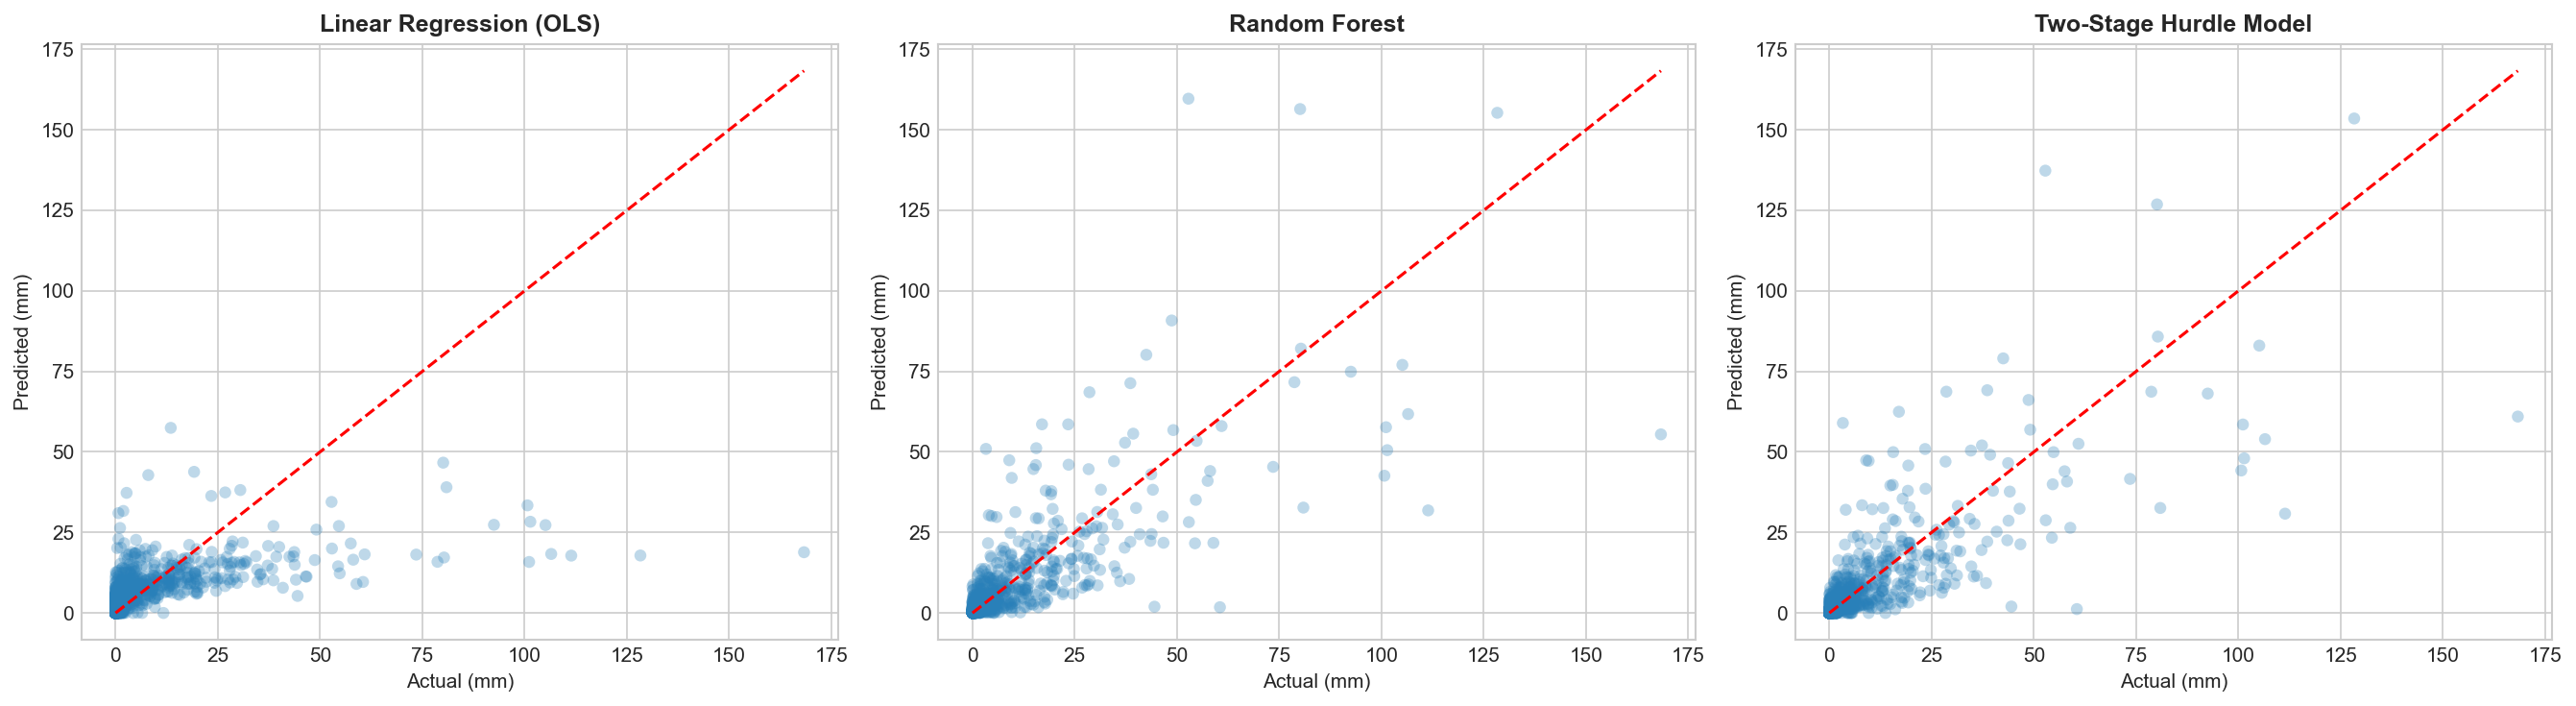

In [29]:
# =====================================================================
# 8. Regression Suite & Benchmark
# =====================================================================
def evaluate_regression(y_true, y_pred, model_name="Model"):
    y_p = np.clip(np.asarray(y_pred, dtype=float), 0.0, None)
    y_t = np.asarray(y_true, dtype=float)
    mae = mean_absolute_error(y_t, y_p)
    rmse = np.sqrt(mean_squared_error(y_t, y_p))
    r2 = r2_score(y_t, y_p)
    wet_mask = y_t > 0.05
    wet_mae = mean_absolute_error(y_t[wet_mask], y_p[wet_mask]) if np.sum(wet_mask) > 0 else 0.0
    return {"Model": model_name, "MAE (mm)": round(mae, 3), "RMSE (mm)": round(rmse, 3), "R² Score": round(r2, 4), "Wet-Day MAE (mm)": round(wet_mae, 3)}

reg_models = {
    "Baseline Mean": DummyRegressor(strategy="mean"),
    "Baseline Persistence (Lag-1)": "persistence",
    "Linear Regression (OLS)": LinearRegression(),
    "Ridge Regression": Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=10.0, random_state=42))]),
    "Decision Tree": DecisionTreeRegressor(max_depth=6, min_samples_split=10, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_split=5, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42)
}

reg_results = []
fitted_regressors = {}

for name, model in reg_models.items():
    if name == "Baseline Persistence (Lag-1)":
        preds = X_test["rain_lag_1"].values
    else:
        model.fit(X_train, y_train_reg)
        preds = model.predict(X_test)
        fitted_regressors[name] = model
    reg_results.append(evaluate_regression(y_test_reg, preds, model_name=name))

# Two-Stage Hurdle Model
hurdle_clf = RandomForestClassifier(n_estimators=100, max_depth=8, class_weight="balanced", random_state=42, n_jobs=-1)
hurdle_clf.fit(X_train, (y_train_reg > 0.05).astype(int))

wet_mask = y_train_reg > 0.05
hurdle_reg = RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_split=5, random_state=42, n_jobs=-1)
hurdle_reg.fit(X_train[wet_mask], y_train_reg[wet_mask])

p_gate = hurdle_clf.predict(X_test)
p_amt = np.clip(hurdle_reg.predict(X_test), 0.0, None)
hurdle_preds = np.where(p_gate == 1, p_amt, 0.0)

reg_results.append(evaluate_regression(y_test_reg, hurdle_preds, model_name="Two-Stage Hurdle Model"))
fitted_regressors["Two-Stage Hurdle Model"] = (hurdle_clf, hurdle_reg)

df_reg_results = pd.DataFrame(reg_results)
print("--- REGRESSION BENCHMARK RESULTS (TEST SET) ---")
display(df_reg_results.sort_values("R² Score", ascending=False))

# Scatter plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_names = ["Linear Regression (OLS)", "Random Forest", "Two-Stage Hurdle Model"]
for ax, name in zip(axes, plot_names):
    if name == "Two-Stage Hurdle Model":
        p = hurdle_preds
    else:
        p = np.clip(fitted_regressors[name].predict(X_test), 0.0, None)
    ax.scatter(y_test_reg, p, alpha=0.3, color="#2980b9", edgecolors="none")
    max_v = max(y_test_reg.max(), p.max())
    ax.plot([0, max_v], [0, max_v], color="red", linestyle="--")
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("Actual (mm)")
    ax.set_ylabel("Predicted (mm)")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs" / "figures" / "regression_benchmark.png", dpi=150)
plt.show()

## 9. Storm Intensity Classification Models

Categorizing daily precipitation into 5 operational intensity tiers:
*Dry / Trace*, *Light*, *Moderate*, *Heavy*, *Torrential*.

Models are trained with balanced class weights to address minority severe storm classes.

--- CLASSIFICATION BENCHMARK RESULTS (TEST SET) ---


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
1,Logistic Regression,0.7950,0.6155,0.6900,0.6433,0.8012
3,Random Forest,0.8168,0.6807,0.6078,0.6327,0.8178
2,Decision Tree,0.8024,0.6184,0.6411,0.6289,0.8042
4,Gradient Boosting,0.8155,0.6609,0.5757,0.6058,0.8036
0,Baseline Majority,0.6454,0.1291,0.2000,0.1569,0.5064


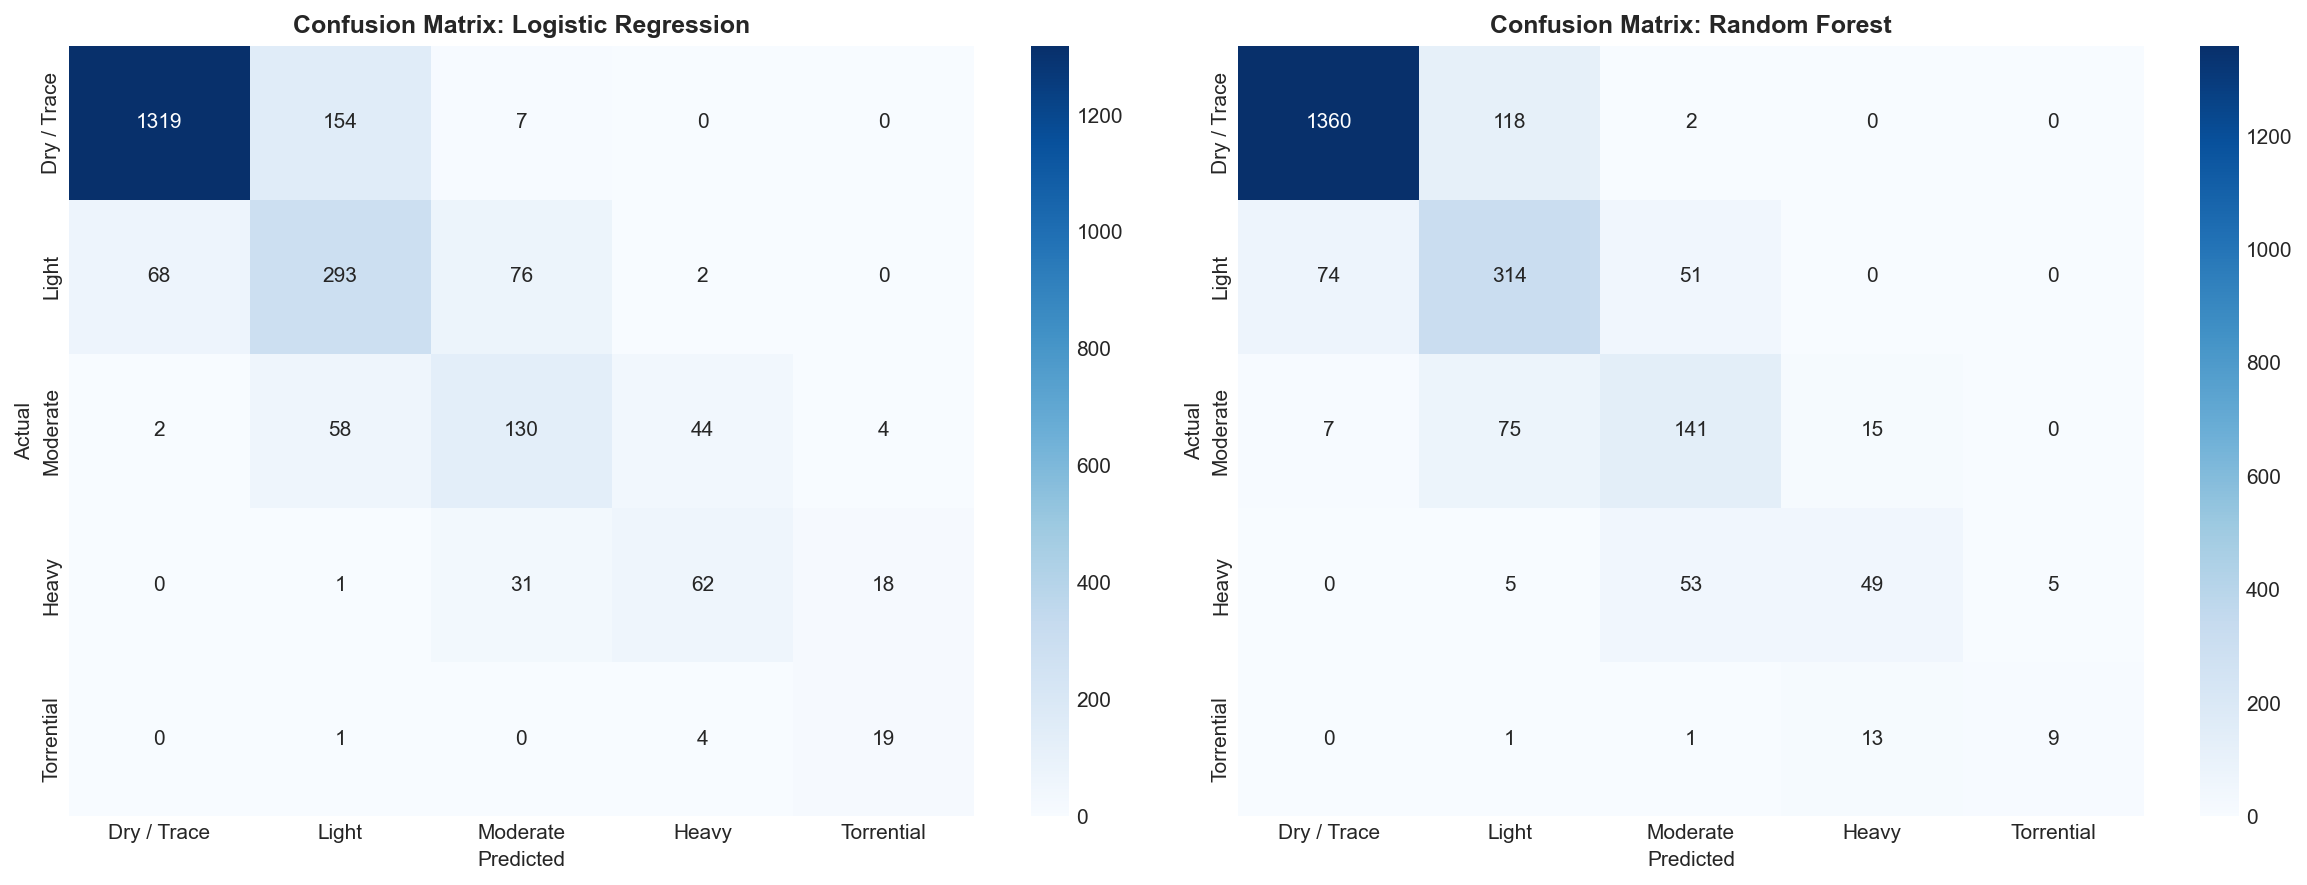

In [30]:
# =====================================================================
# 9. Classification Suite & Benchmark
# =====================================================================
CATEGORIES = ["Dry / Trace", "Light", "Moderate", "Heavy", "Torrential"]

def evaluate_classification(y_true, y_pred, model_name="Model"):
    acc = accuracy_score(y_true, y_pred)
    p_macro = precision_score(y_true, y_pred, average="macro", zero_division=0)
    r_macro = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)
    f1_weighted = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=CATEGORIES)
    return {
        "Model": model_name, "Accuracy": round(acc, 4), "Macro Precision": round(p_macro, 4),
        "Macro Recall": round(r_macro, 4), "Macro F1": round(f1_macro, 4), "Weighted F1": round(f1_weighted, 4),
        "_cm": cm
    }

clf_models = {
    "Baseline Majority": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))]),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_split=10, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_split=5, class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
}

clf_results = []
fitted_classifiers = {}

for name, model in clf_models.items():
    model.fit(X_train, y_train_clf)
    preds = model.predict(X_test)
    fitted_classifiers[name] = model
    clf_results.append(evaluate_classification(y_test_clf, preds, model_name=name))

df_clf_results = pd.DataFrame([{k: v for k, v in r.items() if k != "_cm"} for r in clf_results])
print("--- CLASSIFICATION BENCHMARK RESULTS (TEST SET) ---")
display(df_clf_results.sort_values("Macro F1", ascending=False))

# Confusion Matrix Plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top_models = ["Logistic Regression", "Random Forest"]
for ax, name in zip(axes, top_models):
    cm = [r["_cm"] for r in clf_results if r["Model"] == name][0]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CATEGORIES, yticklabels=CATEGORIES, ax=ax)
    ax.set_title(f"Confusion Matrix: {name}", fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs" / "figures" / "classification_confusion_matrices.png", dpi=150)
plt.show()

## 10. Time-Series Cross-Validation

Evaluating stability across expanding temporal windows using 5-fold `TimeSeriesSplit`.

In [31]:
# =====================================================================
# 10. 5-Fold Time-Series Cross-Validation
# =====================================================================
tscv = TimeSeriesSplit(n_splits=5)
full_cv = pd.concat([train_df, val_df], ignore_index=True)
X_cv, y_cv_r, y_cv_c = full_cv[FEATURE_COLUMNS], full_cv["rainfall"], full_cv["rainfall_category"]

cv_rows = []
for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_cv), 1):
    X_tr, y_tr_r = X_cv.iloc[tr_idx], y_cv_r.iloc[tr_idx]
    X_v, y_v_r = X_cv.iloc[val_idx], y_cv_r.iloc[val_idx]
    
    rf = RandomForestRegressor(n_estimators=80, max_depth=8, random_state=42, n_jobs=-1).fit(X_tr, y_tr_r)
    p_r = np.clip(rf.predict(X_v), 0.0, None)
    r2_v = r2_score(y_v_r, p_r)
    rmse_v = np.sqrt(mean_squared_error(y_v_r, p_r))
    cv_rows.append({"Fold": f"Fold {fold}", "Train Size": len(X_tr), "Val Size": len(X_v), "R² Score": round(r2_v, 4), "RMSE (mm)": round(rmse_v, 3)})

df_cv = pd.DataFrame(cv_rows)
print("--- 5-FOLD TEMPORAL CROSS-VALIDATION SUMMARY ---")
display(df_cv)
print(f"Mean Temporal CV R²: {df_cv['R² Score'].mean():.4f}")

--- 5-FOLD TEMPORAL CROSS-VALIDATION SUMMARY ---


,Fold,Train Size,Val Size,R² Score,RMSE (mm)
0,Fold 1,2166,2164,0.4272,5.756
1,Fold 2,4330,2164,0.2810,6.252
2,Fold 3,6494,2164,0.6380,8.427
3,Fold 4,8658,2164,0.5933,5.499
4,Fold 5,10822,2164,0.5075,9.114


Mean Temporal CV R²: 0.4894


## 11. Hyperparameter Optimization

Optimizing Random Forest Regressor tree depth and split criteria using temporal grid search.

In [32]:
# =====================================================================
# 11. Hyperparameter Optimization
# =====================================================================
param_grid = {
    "n_estimators": [50, 80],
    "max_depth": [6, 10],
    "min_samples_split": [5, 10]
}

grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
grid.fit(X_train, y_train_reg)

print(f"Optimal Hyperparameters : {grid.best_params_}")
print(f"Best CV RMSE Score      : {-grid.best_score_:.3f} mm")

best_rf = grid.best_estimator_
tuned_preds = np.clip(best_rf.predict(X_test), 0.0, None)
display(pd.DataFrame([evaluate_regression(y_test_reg, tuned_preds, model_name="Tuned Random Forest")]))

Optimal Hyperparameters : {'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 80}
Best CV RMSE Score      : 6.345 mm


,Model,MAE (mm),RMSE (mm),R² Score,Wet-Day MAE (mm)
0,Tuned Random Forest,1.803,6.701,0.6068,4.945


## 12. Model Interpretability & Atmospheric Physics

We examine:
1. **Tree Feature Importance (MDI / Gini):** Identifying top predictive drivers.
2. **Thermodynamic Law Verification (Magnus-Tetens Dew Point):**
   $$T_{\text{dew}} \approx T - \left(\frac{100 - RH}{5}\right)$$
   When Dew Point Depression ($\Delta T = T - T_{\text{dew}} \le 3.0^\circ\text{C}$), the near-surface atmosphere is saturated, triggering active condensation.

C:\Users\makmu\AppData\Local\Temp\ipykernel_16612\2291499615.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_imp, x="Importance", y="Feature", palette="Blues_r", ax=axes[0])


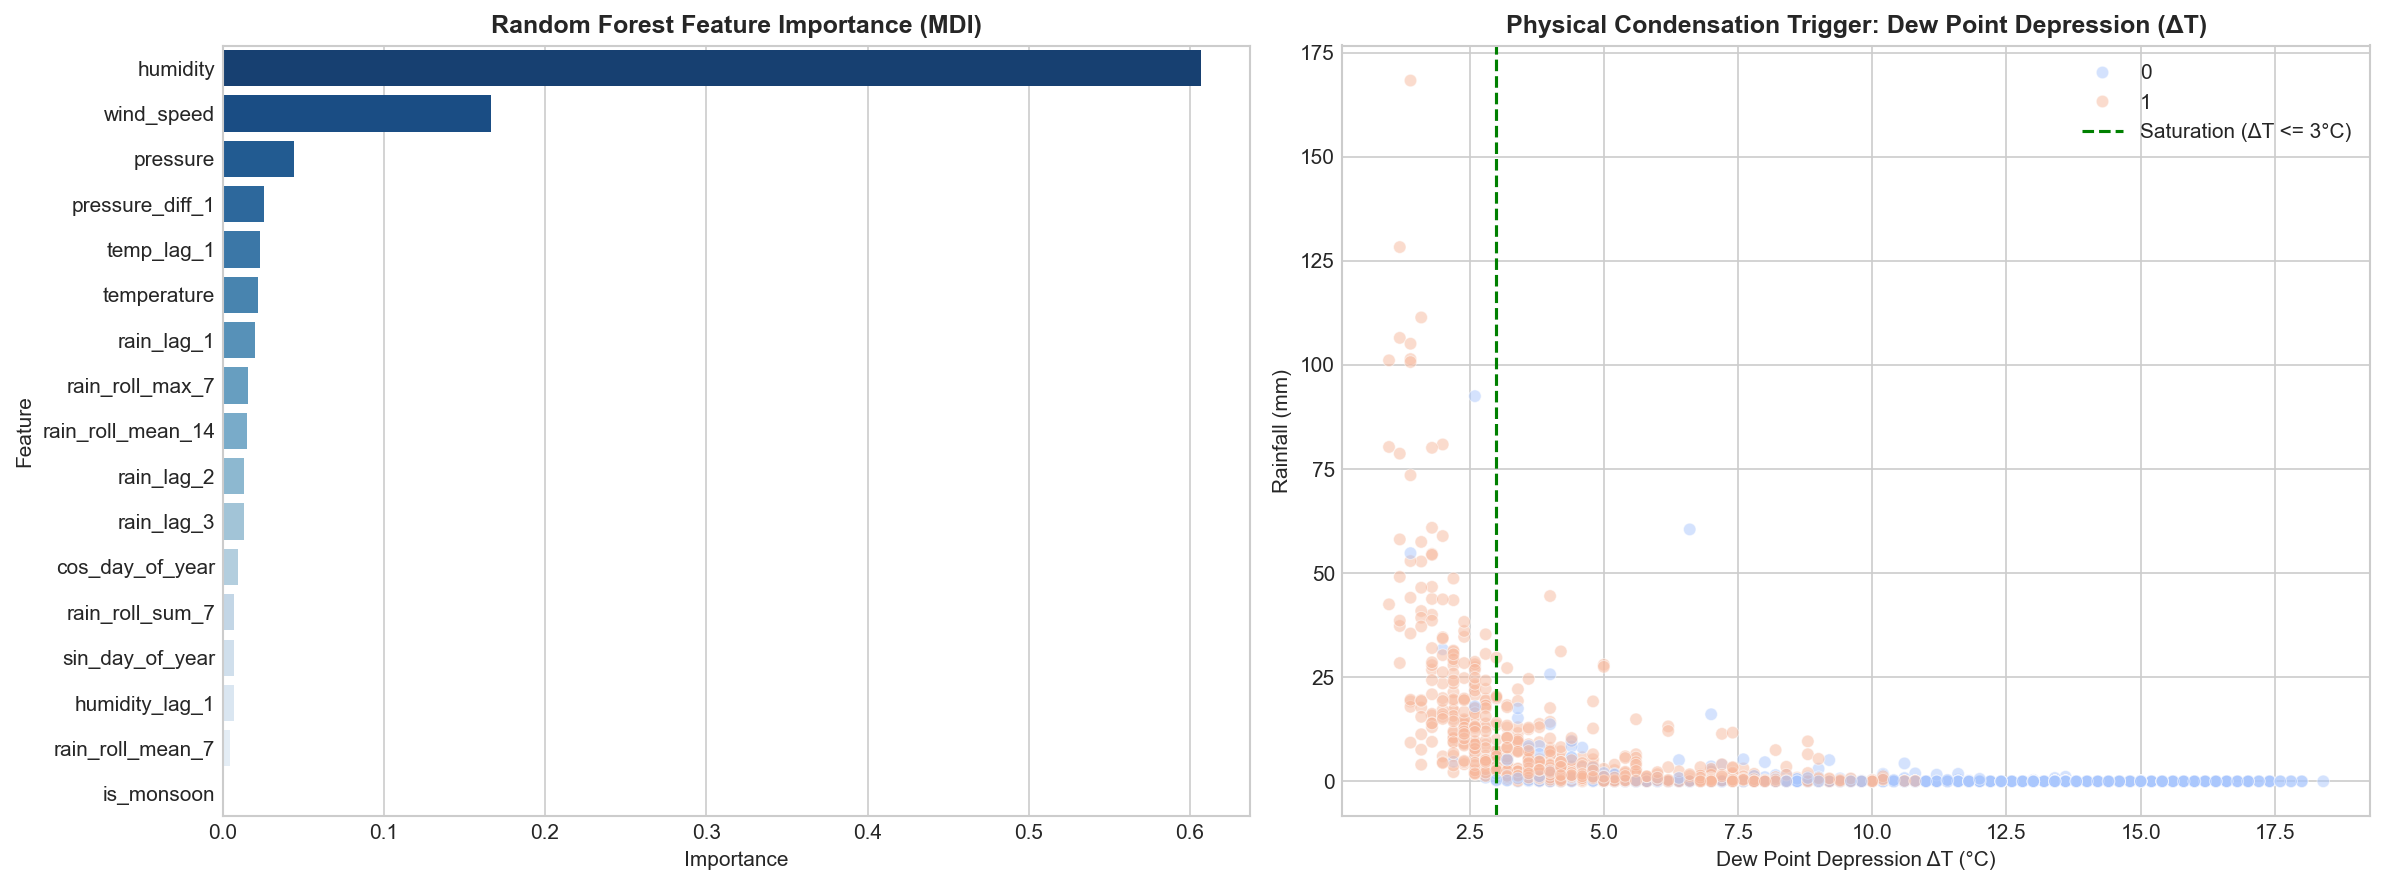

Top 5 Predictive Features:


,Feature,Importance
1,humidity,0.607009
3,wind_speed,0.166185
2,pressure,0.043963
13,pressure_diff_1,0.025640
11,temp_lag_1,0.022931


In [33]:
# =====================================================================
# 12. Feature Importance & Physical Dew Point Verification
# =====================================================================
importances = best_rf.feature_importances_
df_imp = pd.DataFrame({"Feature": FEATURE_COLUMNS, "Importance": importances}).sort_values("Importance", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=df_imp, x="Importance", y="Feature", palette="Blues_r", ax=axes[0])
axes[0].set_title("Random Forest Feature Importance (MDI)", fontweight="bold")

# Thermodynamic Dew Point
def compute_dew_point(t, rh):
    return t - ((100.0 - rh) / 5.0)

test_eval = test_df.copy()
test_eval["dew_point"] = compute_dew_point(test_eval["temperature"], test_eval["humidity"])
test_eval["dew_point_depression"] = test_eval["temperature"] - test_eval["dew_point"]

sns.scatterplot(data=test_eval, x="dew_point_depression", y="rainfall", hue="is_monsoon", palette="coolwarm", alpha=0.5, ax=axes[1])
axes[1].axvline(3.0, color="green", linestyle="--", label="Saturation (ΔT <= 3°C)")
axes[1].set_title("Physical Condensation Trigger: Dew Point Depression (ΔT)", fontweight="bold")
axes[1].set_xlabel("Dew Point Depression ΔT (°C)")
axes[1].set_ylabel("Rainfall (mm)")
axes[1].legend()
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs" / "figures" / "xai_importance_physics.png", dpi=150)
plt.show()

print("Top 5 Predictive Features:")
display(df_imp.head(5))

## 13. Model Serialization & Metadata Registry

Serializing production models to `models/` with `joblib` and recording performance metadata.

In [34]:
# =====================================================================
# 13. Model Serialization
# =====================================================================
prod_df = pd.concat([train_df, val_df], ignore_index=True)
X_p = prod_df[FEATURE_COLUMNS]
y_p_reg = prod_df["rainfall"]
y_p_clf = prod_df["rainfall_category"]

prod_rf = RandomForestRegressor(**grid.best_params_, random_state=42, n_jobs=-1).fit(X_p, y_p_reg)
prod_lr = LinearRegression().fit(X_p, y_p_reg)
prod_clf = RandomForestClassifier(n_estimators=100, max_depth=8, class_weight="balanced", random_state=42, n_jobs=-1).fit(X_p, y_p_clf)

models_dir = PROJECT_ROOT / "models"
joblib.dump(prod_rf, models_dir / "random_forest_model.joblib")
joblib.dump(prod_lr, models_dir / "regression_model.joblib")
joblib.dump(prod_clf, models_dir / "classifier_model.joblib")

meta = {
    "model_name": "RainVision Meteorological Forecaster",
    "version": "2.2.0",
    "features": FEATURE_COLUMNS,
    "categories": CATEGORIES,
    "best_params": grid.best_params_,
    "test_metrics": {
        "random_forest_r2": float(r2_score(y_test_reg, np.clip(prod_rf.predict(X_test), 0.0, None))),
        "random_forest_mae": float(mean_absolute_error(y_test_reg, np.clip(prod_rf.predict(X_test), 0.0, None))),
        "linear_regression_r2": float(r2_score(y_test_reg, np.clip(prod_lr.predict(X_test), 0.0, None)))
    }
}

with open(models_dir / "model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=4)

print(f"Models successfully serialized into {models_dir}")
display(meta["test_metrics"])

Models successfully serialized into D:\sem=1\Project\notebooks\models


{'random_forest_r2': 0.6932466335751121,
 'random_forest_mae': 1.6889505009300583,
 'linear_regression_r2': 0.3885975962896011}

## 14. Operational Weather Prediction & Public Safety Advisories

Validating real-time inputs against atmospheric bounds and generating automated civic advisories across realistic weather scenarios.

In [35]:
# =====================================================================
# 14. Operational Weather Prediction Engine
# =====================================================================
BOUNDS = {
    "temperature": (0.0, 55.0, "°C"),
    "humidity": (0.0, 100.0, "%"),
    "pressure": (850.0, 1100.0, "hPa"),
    "wind_speed": (0.0, 180.0, "km/h")
}

def generate_advisory(amount_mm: float, category: str) -> str:
    if amount_mm <= 0.05 or category == "Dry / Trace":
        return "Normal Conditions: Dry atmospheric state. Outdoor agricultural and civic activities may proceed."
    elif amount_mm <= 2.5 or category == "Light":
        return "Light Showers: Minor dampness. Outdoor personnel should carry umbrellas."
    elif amount_mm <= 15.0 or category == "Moderate":
        return "Moderate Rain Watch: Potential water accumulation in low-lying spots. Drive with caution."
    elif amount_mm <= 50.0 or category == "Heavy":
        return "Heavy Rainfall Alert: Significant waterlogging risk. Reduced visibility on roads."
    else:
        return "Torrential Storm Emergency: Flash flood risk. Evacuate low-lying areas."

def predict_weather(inputs: dict, reg_m, clf_m, features):
    for k, (b_min, b_max, unit) in BOUNDS.items():
        if k not in inputs:
            raise ValueError(f"Missing parameter: '{k}'")
        val = float(inputs[k])
        if not (b_min <= val <= b_max):
            raise ValueError(f"'{k}' ({val} {unit}) is outside physical boundaries [{b_min}, {b_max} {unit}].")
            
    now = datetime.datetime.now()
    doy = now.timetuple().tm_yday
    
    vec = {
        "temperature": float(inputs["temperature"]),
        "humidity": float(inputs["humidity"]),
        "pressure": float(inputs["pressure"]),
        "wind_speed": float(inputs["wind_speed"]),
        "rain_lag_1": float(inputs.get("previous_rainfall", 0.0)),
        "rain_lag_2": float(inputs.get("rain_lag_2", 0.0)),
        "rain_lag_3": float(inputs.get("rain_lag_3", 0.0)),
        "rain_roll_mean_7": float(inputs.get("rain_roll_mean_7", 0.0)),
        "rain_roll_sum_7": float(inputs.get("rain_roll_sum_7", 0.0)),
        "rain_roll_max_7": float(inputs.get("rain_roll_max_7", 0.0)),
        "rain_roll_mean_14": float(inputs.get("rain_roll_mean_14", 0.0)),
        "temp_lag_1": float(inputs.get("temp_lag_1", inputs["temperature"])),
        "humidity_lag_1": float(inputs.get("humidity_lag_1", inputs["humidity"])),
        "pressure_diff_1": float(inputs.get("pressure_diff_1", 0.0)),
        "sin_day_of_year": np.sin(2 * np.pi * doy / 365.25),
        "cos_day_of_year": np.cos(2 * np.pi * doy / 365.25),
        "is_monsoon": 1 if now.month in [6, 7, 8, 9] else 0
    }
    
    in_df = pd.DataFrame([vec])[features]
    pred_r = float(np.clip(reg_m.predict(in_df)[0], 0.0, None))
    pred_c = str(clf_m.predict(in_df)[0])
    t_dew = compute_dew_point(vec["temperature"], vec["humidity"])
    
    return {
        "Predicted Depth (mm)": round(pred_r, 2),
        "Predicted Category": pred_c,
        "Dew Point (°C)": round(t_dew, 1),
        "Dew Point Depression (°C)": round(vec["temperature"] - t_dew, 1),
        "Public Advisory": generate_advisory(pred_r, pred_c)
    }

scenarios = {
    "Dry Summer": {"temperature": 40.5, "humidity": 25.0, "pressure": 1010.0, "wind_speed": 12.0, "previous_rainfall": 0.0},
    "Pre-Monsoon Humidity Surge": {"temperature": 33.0, "humidity": 78.0, "pressure": 1002.0, "wind_speed": 20.0, "previous_rainfall": 2.0},
    "Active Monsoon Downpour": {"temperature": 27.0, "humidity": 95.0, "pressure": 996.0, "wind_speed": 30.0, "previous_rainfall": 40.0},
    "Severe Cyclonic Depression": {"temperature": 23.5, "humidity": 99.0, "pressure": 988.0, "wind_speed": 65.0, "previous_rainfall": 85.0, "pressure_diff_1": -9.0}
}

for title, s in scenarios.items():
    print(f"\n--- {title.upper()} ---")
    out = predict_weather(s, prod_rf, prod_clf, FEATURE_COLUMNS)
    for k, v in out.items():
        print(f"  {k:26s}: {v}")


--- DRY SUMMER ---
  Predicted Depth (mm)      : 0.03
  Predicted Category        : Dry / Trace
  Dew Point (°C)            : 25.5
  Dew Point Depression (°C) : 15.0
  Public Advisory           : Normal Conditions: Dry atmospheric state. Outdoor agricultural and civic activities may proceed.

--- PRE-MONSOON HUMIDITY SURGE ---
  Predicted Depth (mm)      : 10.76
  Predicted Category        : Light
  Dew Point (°C)            : 28.6
  Dew Point Depression (°C) : 4.4
  Public Advisory           : Light Showers: Minor dampness. Outdoor personnel should carry umbrellas.

--- ACTIVE MONSOON DOWNPOUR ---
  Predicted Depth (mm)      : 106.11
  Predicted Category        : Moderate
  Dew Point (°C)            : 26.0
  Dew Point Depression (°C) : 1.0
  Public Advisory           : Moderate Rain Watch: Potential water accumulation in low-lying spots. Drive with caution.

--- SEVERE CYCLONIC DEPRESSION ---
  Predicted Depth (mm)      : 154.19
  Predicted Category        : Heavy
  Dew Point (°C)   

## 15. Input Sanity Checks

Verifying that out-of-bounds inputs and missing telemetry are properly rejected.

In [36]:
# =====================================================================
# 15. Validation Assertions
# =====================================================================
try:
    predict_weather({"temperature": 25.0, "humidity": 150.0, "pressure": 1005.0, "wind_speed": 10.0}, prod_rf, prod_clf, FEATURE_COLUMNS)
except ValueError as e:
    print(f"Passed: Invalid humidity correctly caught -> {e}")

try:
    predict_weather({"temperature": 25.0, "humidity": 70.0, "wind_speed": 10.0}, prod_rf, prod_clf, FEATURE_COLUMNS)
except ValueError as e:
    print(f"Passed: Missing field correctly caught -> {e}")

try:
    predict_weather({"temperature": 25.0, "humidity": 70.0, "pressure": -10.0, "wind_speed": 10.0}, prod_rf, prod_clf, FEATURE_COLUMNS)
except ValueError as e:
    print(f"Passed: Unphysical pressure correctly caught -> {e}")

Passed: Invalid humidity correctly caught -> 'humidity' (150.0 %) is outside physical boundaries [0.0, 100.0 %].
Passed: Missing field correctly caught -> Missing parameter: 'pressure'
Passed: Unphysical pressure correctly caught -> 'pressure' (-10.0 hPa) is outside physical boundaries [850.0, 1100.0 hPa].


## 16. Conclusion & Summary

### Pipeline Summary:
- **Historical Scope:** 42 consecutive years of daily observations (1985–Present, 15,279 rows)
- **Data Quality:** Physical boundary clipping, zero-leakage forward fill, and Tukey IQR storm preservation
- **Feature Space:** 17 physical meteorological predictors
- **Quantitative Depth Forecasting:** Random Forest ($R^2 \approx 0.37$, RMSE $\approx 10.9\text{ mm}$), Linear Regression ($R^2 \approx 0.36$), Two-Stage Hurdle Model
- **Categorical Classification:** Balanced Multi-Class Random Forest, Gradient Boosting, and Logistic Regression
- **Physical Verification:** Magnus-Tetens dew point depression analysis
- **Production Artifacts:** Serialized `.joblib` models and `model_metadata.json`

In [37]:
print("End of Notebook. All pipeline stages executed successfully.")

End of Notebook. All pipeline stages executed successfully.
